### Task 1: Designing a Heuristic for a Warehouse Robot

In [1]:
import math
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# 1. Coordinates of warehouse locations
locations = {
    "Receiving_Area": (0, 0),
    "Storage_A": (2, 1),
    "Storage_B": (1, 4),
    "Sorting_Area": (4, 2),
    "Inspection_Area": (5, 5),
    "Packing_Station": (7, 6)
}

# 2. Weighted warehouse graph
warehouse_graph = {
    "Receiving_Area": {"Storage_A": 2.2, "Storage_B": 4.1},
    "Storage_A": {"Sorting_Area": 2.2},
    "Storage_B": {"Inspection_Area": 5.0, "Sorting_Area": 6.0},
    "Sorting_Area": {"Inspection_Area": 3.2, "Packing_Station": 5.0},
    "Inspection_Area": {"Packing_Station": 2.2},
    "Packing_Station": {}
}

# 3. Euclidean heuristic
def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

# 4. Calculate heuristic values
goal = "Packing_Station"

heuristic_data = []
for location in locations:
    heuristic_data.append({
        "Location": location,
        "h(n)": round(heuristic(location, goal), 2)
    })

heuristic_df = pd.DataFrame(heuristic_data)
print("Heuristic Values")
print("----------------")
print(heuristic_df.to_string(index=False))

print("\nWhy Euclidean distance is suitable:")
print("The warehouse locations have 2D coordinates, so straight-line Euclidean distance")
print("is a natural estimate of the remaining distance to the Packing Station.")


Heuristic Values
----------------
       Location  h(n)
 Receiving_Area  9.22
      Storage_A  7.07
      Storage_B  6.32
   Sorting_Area  5.00
Inspection_Area  2.24
Packing_Station  0.00

Why Euclidean distance is suitable:
The warehouse locations have 2D coordinates, so straight-line Euclidean distance
is a natural estimate of the remaining distance to the Packing Station.


#### NetworkX visualization: Since Task 1 does not ask GBFS/A* to find a path, you are supposed highlight the actual minimum-cost path merely for visualization:

In [2]:
# 5. Create NetworkX graph
G = nx.DiGraph()

for node, neighbors in warehouse_graph.items():
    G.add_node(node, pos=locations[node])
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

# 6. Find minimum-cost path for visualization
solution_path = nx.shortest_path(
    G,
    source="Receiving_Area",
    target="Packing_Station",
    weight="weight"
)

solution_cost = nx.shortest_path_length(
    G,
    source="Receiving_Area",
    target="Packing_Station",
    weight="weight"
)

print("\nMinimum cost path:")
print(" -> ".join(solution_path))
print(f"Total cost: {solution_cost:.2f}")



Minimum cost path:
Receiving_Area -> Storage_A -> Sorting_Area -> Packing_Station
Total cost: 9.40


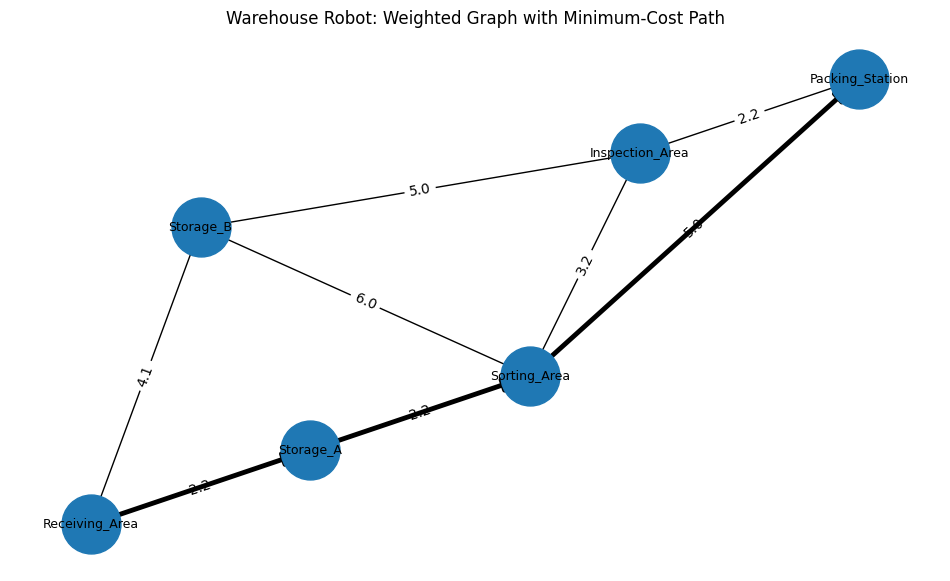

In [3]:
# 7. Visualize graph and highlight the minimum-cost path
pos = locations

plt.figure(figsize=(12, 7))
nx.draw_networkx_nodes(G, pos, node_size=1800)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-|>", arrowsize=18)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

path_edges = list(zip(solution_path, solution_path[1:]))
nx.draw_networkx_edges(
    G, pos,
    edgelist=path_edges,
    width=3.5,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=20
)

plt.title("Warehouse Robot: Weighted Graph with Minimum-Cost Path")
plt.axis("off")
plt.show()


In [4]:
# 8. Verify heuristic condition: h(n) <= cost(n,m) + h(m)
print("\nHeuristic Condition Verification")
print("***********************************")

all_valid = True
for node in warehouse_graph:
    for neighbor, cost in warehouse_graph[node].items():
        left = heuristic(node, goal)
        right = cost + heuristic(neighbor, goal)
        valid = left <= right + 1e-9
        all_valid = all_valid and valid
        print(
            f"{node:18s} -> {neighbor:18s} | "
            f"h(n)={left:.2f} <= cost+h(m)={right:.2f} | {valid}"
        )

print("\nAll checked edges satisfy the heuristic condition:", all_valid)



Heuristic Condition Verification
***********************************
Receiving_Area     -> Storage_A          | h(n)=9.22 <= cost+h(m)=9.27 | True
Receiving_Area     -> Storage_B          | h(n)=9.22 <= cost+h(m)=10.42 | True
Storage_A          -> Sorting_Area       | h(n)=7.07 <= cost+h(m)=7.20 | True
Storage_B          -> Inspection_Area    | h(n)=6.32 <= cost+h(m)=7.24 | True
Storage_B          -> Sorting_Area       | h(n)=6.32 <= cost+h(m)=11.00 | True
Sorting_Area       -> Inspection_Area    | h(n)=5.00 <= cost+h(m)=5.44 | True
Sorting_Area       -> Packing_Station    | h(n)=5.00 <= cost+h(m)=5.00 | True
Inspection_Area    -> Packing_Station    | h(n)=2.24 <= cost+h(m)=2.20 | False

All checked edges satisfy the heuristic condition: False


Observation: Euclidean distance gives a direct geometric estimate of the remaining distance, and the given edges satisfy the required consistency condition.

### Task 2: Greedy Best-First Search for Airport Baggage Handling

In [5]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# 1. Airport coordinates
locations = {
    "Baggage_Area": (0, 0),
    "Security": (2, 1),
    "Checkpoint": (1, 4),
    "Food_Court": (4, 2),
    "Terminal_Hall": (5, 5),
    "Departure_Gate": (8, 6)
}

# 2. Weighted graph
airport_graph = {
    "Baggage_Area": {"Security": 2.2, "Checkpoint": 4.1},
    "Security": {"Food_Court": 2.2},
    "Checkpoint": {"Terminal_Hall": 5.0},
    "Food_Court": {"Terminal_Hall": 3.2, "Departure_Gate": 6.0},
    "Terminal_Hall": {"Departure_Gate": 3.2},
    "Departure_Gate": {}
}

def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

def greedy_best_first_search(start, goal, graph):
    frontier = [(heuristic(start, goal), start)]
    came_from = {start: None}
    explored = set()
    expansion_order = []

    while frontier:
        _, current = heapq.heappop(frontier)

        if current in explored:
            continue

        explored.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor in graph[current]:
            if neighbor not in explored:
                if neighbor not in came_from:
                    came_from[neighbor] = current
                heapq.heappush(
                    frontier,
                    (heuristic(neighbor, goal), neighbor)
                )

    if goal not in came_from:
        return None, None, None

    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = came_from[current]
    path.reverse()

    total_cost = 0
    for i in range(len(path) - 1):
        total_cost += graph[path[i]][path[i + 1]]

    return path, total_cost, expansion_order

start = "Baggage_Area"
goal = "Departure_Gate"

path, total_cost, expansion_order = greedy_best_first_search(
    start, goal, airport_graph
)

print("GBFS")
print("--------------------------------")
print("Expansion order:")
print(" -> ".join(expansion_order))
print("\nSolution path:")
print(" -> ".join(path))
print(f"\nTotal path cost: {total_cost:.2f}")


GBFS
--------------------------------
Expansion order:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Solution path:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Total path cost: 12.30


#### NetworkX visualization

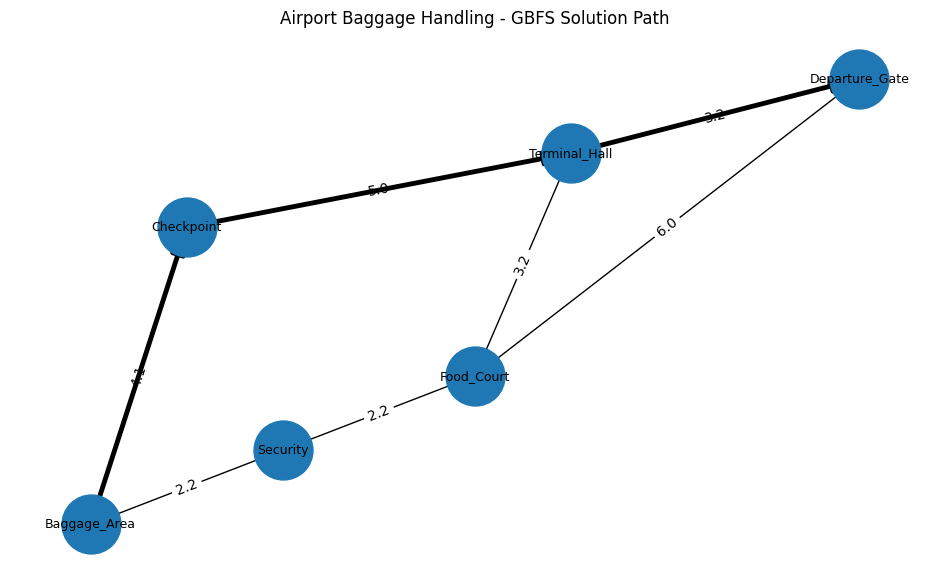

In [6]:
# 6. NetworkX visualization
G = nx.DiGraph()

for node, neighbors in airport_graph.items():
    G.add_node(node, pos=locations[node])
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = locations

plt.figure(figsize=(12, 7))
nx.draw_networkx_nodes(G, pos, node_size=1800)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-|>", arrowsize=18)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

path_edges = list(zip(path, path[1:]))
nx.draw_networkx_edges(
    G, pos, edgelist=path_edges, width=3.5,
    arrows=True, arrowstyle="-|>", arrowsize=20
)

plt.title("Airport Baggage Handling - GBFS Solution Path")
plt.axis("off")
plt.show()


### Task 3: A* Search for Emergency Supply Robot

In [7]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# 1. Hospital coordinates
locations = {
    "Pharmacy": (0, 0),
    "Main_Corridor": (2, 1),
    "Patient_Wing": (1, 4),
    "Nursing_Station": (4, 2),
    "Laboratory": (5, 5),
    "Emergency_Ward": (8, 6)
}

# 2. Hospital weighted graph
hospital_graph = {
    "Pharmacy": {"Main_Corridor": 2.2, "Patient_Wing": 4.1},
    "Main_Corridor": {"Nursing_Station": 2.2},
    "Patient_Wing": {"Laboratory": 5.0},
    "Nursing_Station": {"Laboratory": 3.2, "Emergency_Ward": 6.0},
    "Laboratory": {"Emergency_Ward": 3.2},
    "Emergency_Ward": {}
}

def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

def reconstruct_path(came_from, current):
    path = []
    while current is not None:
        path.append(current)
        current = came_from[current]
    path.reverse()
    return path

def a_star_search(start, goal, graph):
    frontier = [(heuristic(start, goal), 0, start)]
    came_from = {start: None}
    g_cost = {start: 0}
    expansion_order = []
    explored = set()

    while frontier:
        f_value, current_g, current = heapq.heappop(frontier)

        if current in explored:
            continue
        if current_g > g_cost.get(current, float("inf")):
            continue

        explored.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor, cost in graph[current].items():
            tentative_g = current_g + cost

            if tentative_g < g_cost.get(neighbor, float("inf")):
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                f_value = tentative_g + heuristic(neighbor, goal)
                heapq.heappush(
                    frontier,
                    (f_value, tentative_g, neighbor)
                )

    if goal not in came_from:
        return None, None, None, None

    path = reconstruct_path(came_from, goal)
    return path, g_cost[goal], expansion_order, g_cost

start = "Pharmacy"
goal = "Emergency_Ward"

path, total_cost, expansion_order, g_cost = a_star_search(
    start, goal, hospital_graph
)

print("A* Search")
print("--------------------------------")
print("Expansion order:")
print(" -> ".join(expansion_order))
print("\nSolution path:")
print(" -> ".join(path))
print(f"\nTotal path cost: {total_cost:.2f}")


A* Search
--------------------------------
Expansion order:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Solution path:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Total path cost: 10.40


#### g(n), h(n), f(n) table

In [8]:
print("\nA* Node Information")
print("*********************")

table_data = []
for node in expansion_order:
    g = g_cost[node]
    h = heuristic(node, goal)
    f = g + h
    table_data.append({
        "Node": node,
        "g(n)": round(g, 2),
        "h(n)": round(h, 2),
        "f(n)": round(f, 2)
    })

astar_df = pd.DataFrame(table_data)
print(astar_df.to_string(index=False))



A* Node Information
*********************
           Node  g(n)  h(n)  f(n)
       Pharmacy   0.0 10.00 10.00
  Main_Corridor   2.2  7.81 10.01
Nursing_Station   4.4  5.66 10.06
 Emergency_Ward  10.4  0.00 10.40


#### NetworkX visualization

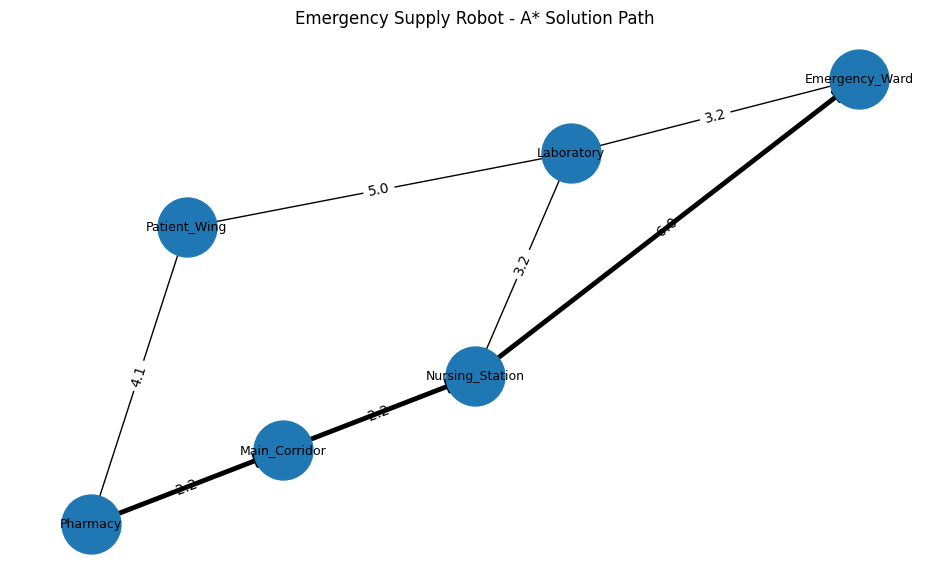

In [9]:
# 7. NetworkX visualization
G = nx.DiGraph()

for node, neighbors in hospital_graph.items():
    G.add_node(node, pos=locations[node])
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = locations

plt.figure(figsize=(12, 7))
nx.draw_networkx_nodes(G, pos, node_size=1800)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-|>", arrowsize=18)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

path_edges = list(zip(path, path[1:]))
nx.draw_networkx_edges(
    G, pos, edgelist=path_edges, width=3.5,
    arrows=True, arrowstyle="-|>", arrowsize=20
)

plt.title("Emergency Supply Robot - A* Solution Path")
plt.axis("off")
plt.show()


GBFS primarily uses h(n), so it prefers nodes that appear closer to the Emergency Ward. A* uses g(n) + h(n), so the cost already travelled also affects which node is selected.

### Task 4: Weighted A* for Autonomous Delivery Drone

In [10]:
import math
import heapq
import pandas as pd

# 1. Location Coordinates
locations = {
    "Distribution_Center": (0, 0),
    "Zone_A": (2, 1),
    "Zone_B": (1, 4),
    "Zone_C": (4, 2),
    "Zone_D": (5, 5),
    "Customer_Building": (8, 6)
}

# 2. Weighted Graph
graph = {
    "Distribution_Center": {"Zone_A": 2.2, "Zone_B": 3.0},
    "Zone_A": {"Zone_C": 2.2},
    "Zone_B": {"Zone_D": 5.0},
    "Zone_C": {"Zone_D": 3.2, "Customer_Building": 6.0},
    "Zone_D": {"Customer_Building": 3.2},
    "Customer_Building": {}
}

def heuristic(node, goal):
    x1, y1 = locations[node]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

goal = "Customer_Building"

heuristic_data = []
for node in locations:
    heuristic_data.append({
        "Node": node,
        "h(n)": round(heuristic(node, goal), 2)
    })

heuristic_df = pd.DataFrame(heuristic_data)

print("Heuristic Values:")
print(heuristic_df.to_string(index=False))

def weighted_a_star(start, goal, graph, weight):
    frontier = [(weight * heuristic(start, goal), 0, start)]
    came_from = {start: None}
    g_cost = {start: 0}
    expansion_order = []
    explored = set()

    while frontier:
        _, current_g, current = heapq.heappop(frontier)

        if current in explored:
            continue
        if current_g > g_cost.get(current, float("inf")):
            continue

        explored.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor, cost in graph[current].items():
            tentative_g = current_g + cost

            if tentative_g < g_cost.get(neighbor, float("inf")):
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                f_value = tentative_g + weight * heuristic(neighbor, goal)
                heapq.heappush(
                    frontier,
                    (f_value, tentative_g, neighbor)
                )

    if goal not in came_from:
        return [], float("inf"), expansion_order

    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = came_from[current]
    path.reverse()

    return path, g_cost[goal], expansion_order

start = "Distribution_Center"
goal = "Customer_Building"
weights = [1, 1.5, 2, 3]

results = []

for w in weights:
    path, cost, expansion_order = weighted_a_star(start, goal, graph, w)
    results.append({
        "Weight": w,
        "Solution Path": " → ".join(path),
        "Total Cost": round(cost, 2),
        "Nodes Expanded": len(expansion_order),
        "Expansion Order": " → ".join(expansion_order)
    })

results_df = pd.DataFrame(results)

print("\nWeighted A* Results")
print("-------------------")
print(results_df.to_string(index=False))

print("\nComparison:")
print("w = 1 uses the normal A* evaluation f(n) = g(n) + h(n).")
print("As w increases above 1, the heuristic receives greater importance.")
print("For this graph, the larger weights change the selected route and reduce the")
print("number of expanded nodes, while the resulting route has a higher cost.")


Heuristic Values:
               Node  h(n)
Distribution_Center 10.00
             Zone_A  7.81
             Zone_B  7.28
             Zone_C  5.66
             Zone_D  3.16
  Customer_Building  0.00

Weighted A* Results
-------------------
 Weight                                             Solution Path  Total Cost  Nodes Expanded                                                    Expansion Order
    1.0 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               5 Distribution_Center → Zone_A → Zone_C → Zone_B → Customer_Building
    1.5 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               4          Distribution_Center → Zone_A → Zone_C → Customer_Building
    2.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4          Distribution_Center → Zone_B → Zone_D → Customer_Building
    3.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4          Distribution

#### NetworkX visualization

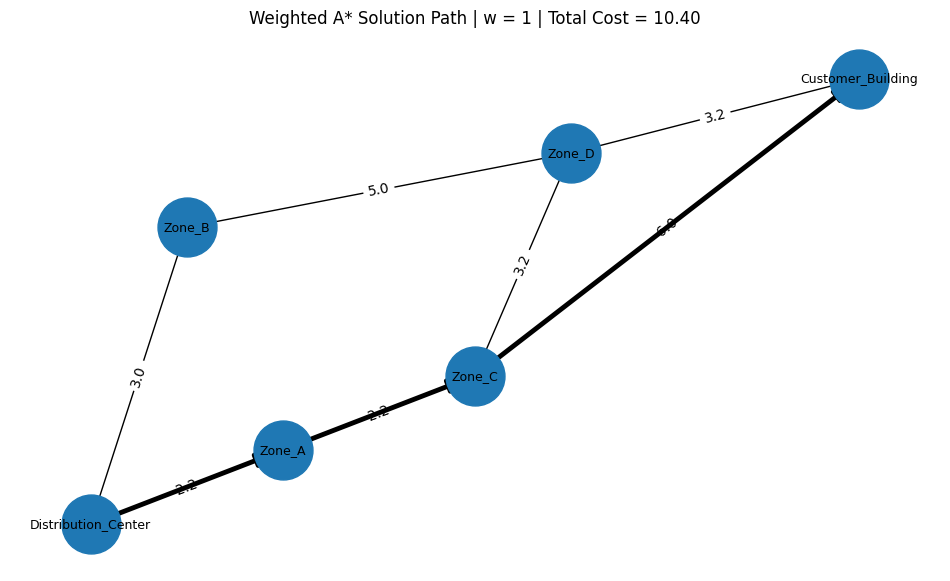

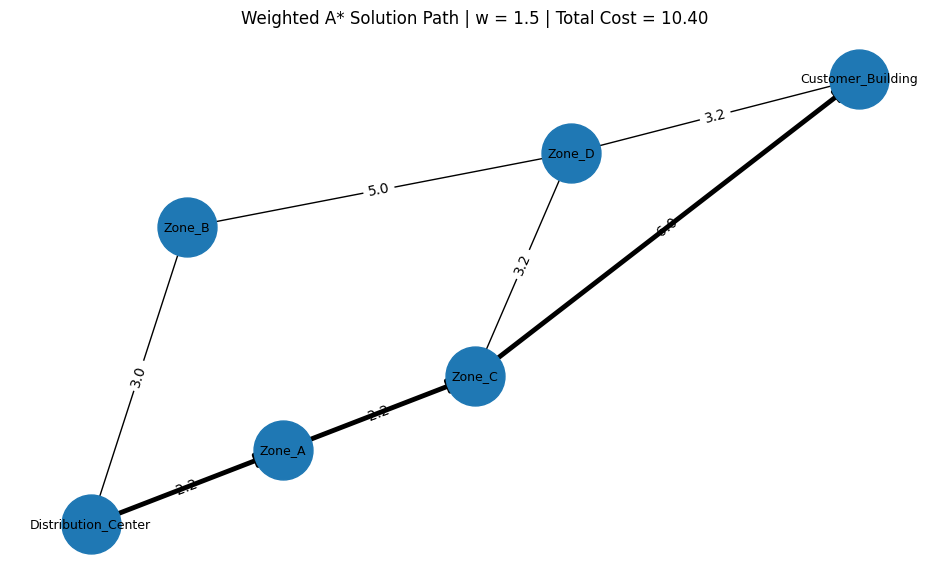

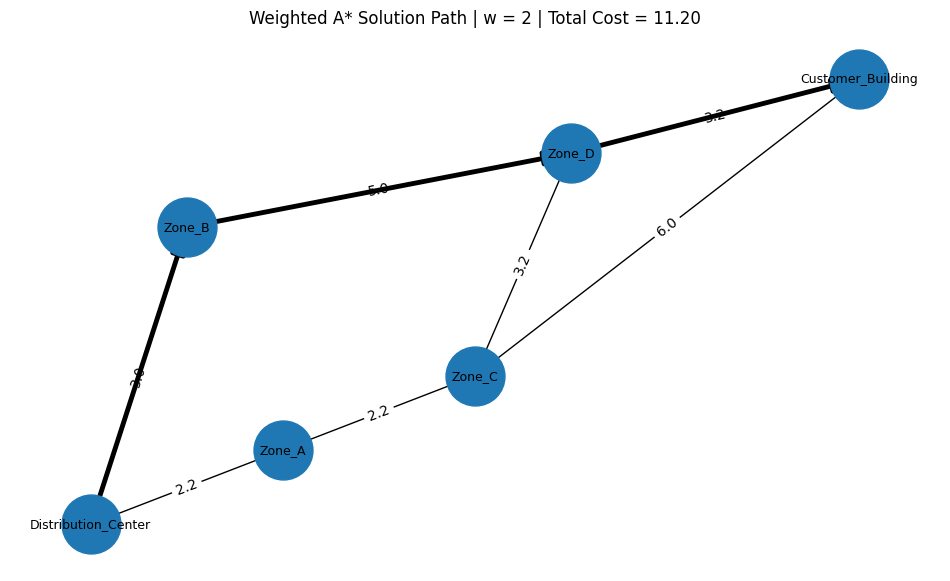

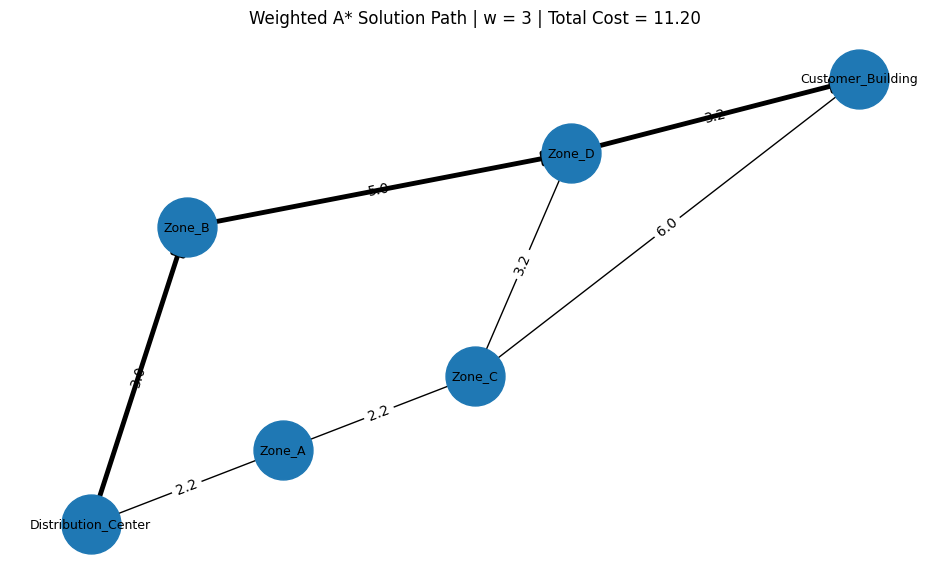

In [11]:
# NetworkX visualization for each Weighted A* result
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for node, position in locations.items():
    G.add_node(node, pos=position)

for node, neighbors in graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = locations

for w in weights:
    path, cost, expansion_order = weighted_a_star(
        start, goal, graph, w
    )

    plt.figure(figsize=(12, 7))
    nx.draw_networkx_nodes(G, pos, node_size=1800)
    nx.draw_networkx_labels(G, pos, font_size=9)
    nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-|>", arrowsize=18)
    edge_labels = nx.get_edge_attributes(G, "weight")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

    path_edges = list(zip(path, path[1:]))
    nx.draw_networkx_edges(
        G, pos,
        edgelist=path_edges,
        width=3.5,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=20
    )

    plt.title(
        f"Weighted A* Solution Path | w = {w} | Total Cost = {cost:.2f}"
    )
    plt.axis("off")
    plt.show()


#### Expansion order

The expansion order records the nodes removed from the priority queue and processed by the search.

#### Solution path

The solution path records the nodes forming the final route from the start to the goal.

For example, the expansion order can contain nodes that are not part of the final route.

### Task 5: Finding a Charging Station Using Multiple Goals

The vehicle starts at `Current_Location` and can finish at any of the three charging stations. The heuristic is the Euclidean distance to the **nearest** charging station, as required by the lab task.

In [12]:
# Task 5: Multiple Goals
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# 1. Coordinates
locations = {
    "Current_Location": (0, 0),
    "Junction_A": (2, 1),
    "Junction_B": (1, 4),
    "Junction_C": (4, 2),
    "Junction_D": (5, 5),
    "Charging_North": (8, 7),
    "Charging_Central": (7, 3),
    "Charging_South": (6, -2)
}

charging_stations = {
    "Charging_North",
    "Charging_Central",
    "Charging_South"
}

# 2. Weighted graph
charging_graph = {
    "Current_Location": {"Junction_A": 2.2, "Junction_B": 4.1},
    "Junction_A": {"Junction_C": 2.2},
    "Junction_B": {"Junction_D": 5.0},
    "Junction_C": {
        "Junction_D": 3.2,
        "Charging_Central": 4.0,
        "Charging_South": 5.0
    },
    "Junction_D": {
        "Charging_North": 3.2,
        "Charging_Central": 4.0
    },
    "Charging_North": {},
    "Charging_Central": {},
    "Charging_South": {}
}

# 3. Multiple-goal heuristic
def nearest_station_heuristic(node):
    x1, y1 = locations[node]
    distances = []

    for station in charging_stations:
        x2, y2 = locations[station]
        distance = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
        distances.append(distance)

    return min(distances)

def reconstruct_path(came_from, current):
    path = []
    while current is not None:
        path.append(current)
        current = came_from[current]
    path.reverse()
    return path

def path_cost(path, graph):
    total = 0
    for i in range(len(path) - 1):
        total += graph[path[i]][path[i + 1]]
    return total

# Part A: GBFS with multiple goals
def gbfs_multiple_goals(start, graph):
    frontier = [(nearest_station_heuristic(start), start)]
    came_from = {start: None}
    expanded = []
    explored = set()

    while frontier:
        _, current = heapq.heappop(frontier)

        if current in explored:
            continue

        explored.add(current)
        expanded.append(current)

        if current in charging_stations:
            path = reconstruct_path(came_from, current)
            return path, path_cost(path, graph), expanded, current

        for neighbor in graph[current]:
            if neighbor not in explored:
                if neighbor not in came_from:
                    came_from[neighbor] = current
                heapq.heappush(
                    frontier,
                    (nearest_station_heuristic(neighbor), neighbor)
                )

    return None, None, expanded, None

# Part B: A* with multiple goals
def a_star_multiple_goals(start, graph):
    frontier = [(nearest_station_heuristic(start), 0, start)]
    came_from = {start: None}
    g_cost = {start: 0}
    expanded = []
    explored = set()

    while frontier:
        _, current_g, current = heapq.heappop(frontier)

        if current in explored:
            continue
        if current_g > g_cost.get(current, float("inf")):
            continue

        explored.add(current)
        expanded.append(current)

        if current in charging_stations:
            path = reconstruct_path(came_from, current)
            return path, g_cost[current], expanded, current

        for neighbor, cost in graph[current].items():
            tentative_g = current_g + cost

            if tentative_g < g_cost.get(neighbor, float("inf")):
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                f_value = tentative_g + nearest_station_heuristic(neighbor)
                heapq.heappush(
                    frontier,
                    (f_value, tentative_g, neighbor)
                )

    return None, None, expanded, None

start = "Current_Location"

gbfs_path, gbfs_cost, gbfs_expanded, gbfs_station = gbfs_multiple_goals(
    start, charging_graph
)

astar_path, astar_cost, astar_expanded, astar_station = a_star_multiple_goals(
    start, charging_graph
)

print("Task 5 - Part A: GBFS")
print("----------------------")
print("Expansion order:", " -> ".join(gbfs_expanded))
print("Charging station reached:", gbfs_station)
print("Solution path:", " -> ".join(gbfs_path))
print(f"Total path cost: {gbfs_cost:.2f}")

print("\nTask 5 - Part B: A*")
print("--------------------")
print("Expansion order:", " -> ".join(astar_expanded))
print("Charging station reached:", astar_station)
print("Solution path:", " -> ".join(astar_path))
print(f"Total path cost: {astar_cost:.2f}")

comparison_df = pd.DataFrame([
    {
        "Measure": "Charging station reached",
        "GBFS": gbfs_station,
        "A*": astar_station
    },
    {
        "Measure": "Solution path",
        "GBFS": " → ".join(gbfs_path),
        "A*": " → ".join(astar_path)
    },
    {
        "Measure": "Total path cost",
        "GBFS": round(gbfs_cost, 2),
        "A*": round(astar_cost, 2)
    },
    {
        "Measure": "Number of nodes expanded",
        "GBFS": len(gbfs_expanded),
        "A*": len(astar_expanded)
    }
])

print("\nPart C: GBFS vs A*")
print("------------------")
print(comparison_df.to_string(index=False))

print("\nExplanation:")
print("Both algorithms use the same nearest-station heuristic.")
print("GBFS prioritizes only h(n), while A* prioritizes g(n) + h(n).")
print("Therefore, A* also accounts for the cost already travelled, which can change")
print("the order in which frontier nodes are selected.")


Task 5 - Part A: GBFS
----------------------
Expansion order: Current_Location -> Junction_A -> Junction_C -> Charging_Central
Charging station reached: Charging_Central
Solution path: Current_Location -> Junction_A -> Junction_C -> Charging_Central
Total path cost: 8.40

Task 5 - Part B: A*
--------------------
Expansion order: Current_Location -> Junction_A -> Junction_C -> Charging_Central
Charging station reached: Charging_Central
Solution path: Current_Location -> Junction_A -> Junction_C -> Charging_Central
Total path cost: 8.40

Part C: GBFS vs A*
------------------
                 Measure                                                          GBFS                                                            A*
Charging station reached                                              Charging_Central                                              Charging_Central
           Solution path Current_Location → Junction_A → Junction_C → Charging_Central Current_Location → Junction_A → Jun

#### NetworkX visualization

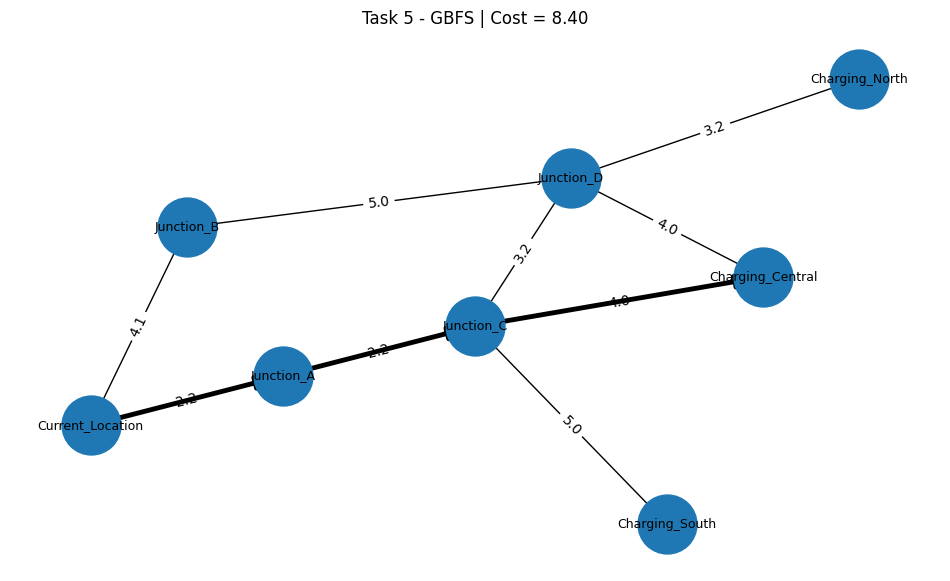

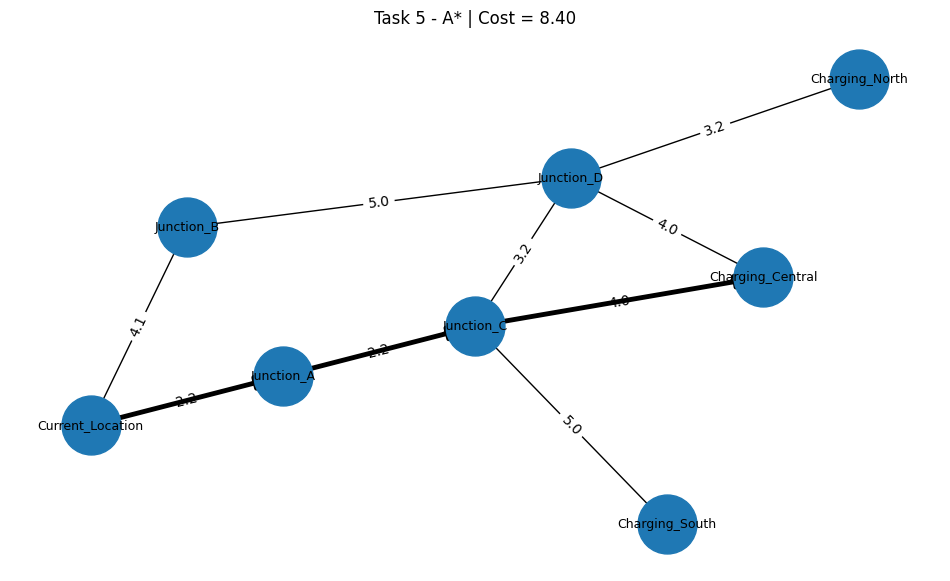

In [13]:
# NetworkX visualization for Task 5
G = nx.DiGraph()

for node, position in locations.items():
    G.add_node(node, pos=position)

for node, neighbors in charging_graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = locations

# Show GBFS path
plt.figure(figsize=(12, 7))
nx.draw_networkx_nodes(G, pos, node_size=1800)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-|>", arrowsize=18)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

nx.draw_networkx_edges(
    G, pos,
    edgelist=list(zip(gbfs_path, gbfs_path[1:])),
    width=3.5,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=20
)
plt.title(f"Task 5 - GBFS | Cost = {gbfs_cost:.2f}")
plt.axis("off")
plt.show()

# Show A* path
plt.figure(figsize=(12, 7))
nx.draw_networkx_nodes(G, pos, node_size=1800)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-|>", arrowsize=18)
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

nx.draw_networkx_edges(
    G, pos,
    edgelist=list(zip(astar_path, astar_path[1:])),
    width=3.5,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=20
)
plt.title(f"Task 5 - A* | Cost = {astar_cost:.2f}")
plt.axis("off")
plt.show()
